In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("card_transdata.csv")

df.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
1,10.829943,0.175592,1.294219,1.0,NaN,0.0,0.0,0
2,5.091079,NaN,0.427715,1.0,0.0,0.0,1.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0


In [2]:
df.shape

(999, 8)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   distance_from_home              999 non-null    float64
 1   distance_from_last_transaction  996 non-null    float64
 2   ratio_to_median_purchase_price  997 non-null    float64
 3   repeat_retailer                 992 non-null    float64
 4   used_chip                       995 non-null    float64
 5   used_pin_number                 997 non-null    float64
 6   online_order                    995 non-null    float64
 7   fraud                           999 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 62.6 KB


In [4]:
df.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
1,10.829943,0.175592,1.294219,1.0,NaN,0.0,0.0,0
2,5.091079,NaN,0.427715,1.0,0.0,0.0,1.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0


In [5]:
df.tail()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
994,3.005300,1.326847,2.583335,1.0,0.0,0.0,1.0,0
995,9.873417,1.022586,0.346643,1.0,0.0,0.0,0.0,0
996,168.091703,6.304360,0.416833,1.0,1.0,0.0,0.0,0
997,44.047622,0.510298,0.624706,1.0,0.0,0.0,1.0,0
998,2.998418,0.193681,0.743416,1.0,1.0,0.0,1.0,0


In [6]:
df.describe()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
count,999.000000,996.000000,997.000000,992.000000,995.000000,997.000000,995.000000,999.000000
mean,26.876607,5.437319,1.655069,0.892137,0.313568,0.117352,0.673367,0.079079
std,63.899697,35.668094,2.351386,0.310364,0.464176,0.322001,0.469218,0.269997
min,0.104184,0.001448,0.016933,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.990543,0.306441,0.468123,1.000000,0.000000,0.000000,0.000000,0.000000
50%,10.340321,0.958539,0.955504,1.000000,0.000000,0.000000,1.000000,0.000000
75%,25.393952,3.137259,1.922025,1.000000,1.000000,0.000000,1.000000,0.000000
max,965.910612,990.070315,36.074366,1.000000,1.000000,1.000000,1.000000,1.000000


In [7]:
df.isnull().sum()

distance_from_home                0
distance_from_last_transaction    3
ratio_to_median_purchase_price    2
repeat_retailer                   7
used_chip                         4
used_pin_number                   2
online_order                      4
fraud                             0
dtype: int64

In [8]:
(df.isnull().sum().sum() / df.size) * 100

np.float64(0.2752752752752753)

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df['fraud'].value_counts()

fraud
0    920
1     79
Name: count, dtype: int64

In [11]:
df['fraud'].value_counts(normalize=True) * 100

fraud
0    92.092092
1     7.907908
Name: proportion, dtype: float64

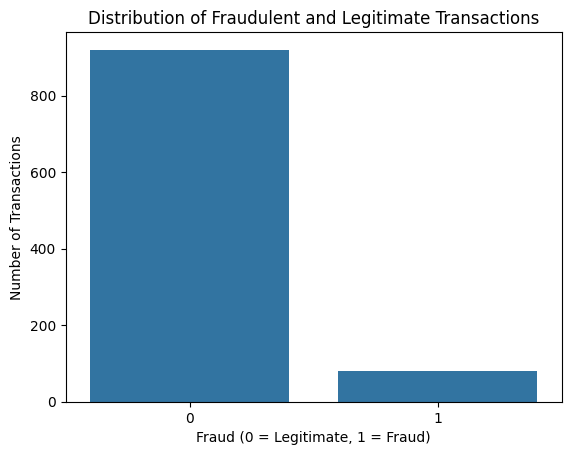

In [12]:
sns.countplot(data=df, x='fraud')

plt.title('Distribution of Fraudulent and Legitimate Transactions')
plt.xlabel('Fraud (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Number of Transactions')

plt.show()

In [13]:
df.groupby('fraud').mean(numeric_only=True)

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order
fraud,,,,,,,
0,21.276513,4.706198,1.357216,0.889497,0.326063,0.127451,0.647764
1,92.092892,13.923878,5.116192,0.923077,0.166667,0.000000,0.974359


In [14]:
df.groupby('fraud').describe()

distance_from_home                                             \
                   count       mean         std       min       25%   
fraud                                                                 
0                  920.0  21.276513   39.418736  0.104184  3.843739   
1                   79.0  92.092892  171.051680  0.633633  7.953386   

                                         distance_from_last_transaction  \
             50%         75%         max                          count   
fraud                                                                     
0       9.595149   24.317974  765.282559                          917.0   
1      19.613741  105.130609  965.910612                           79.0   

                  ... used_pin_number      online_order                      \
            mean  ...             75%  max        count      mean       std   
fraud             ...                                                         
0       4.706198  ...             0.0  1.0        917.0  0.647764  0.477928   
1      13.923878  ...             0.0  0.0         78.0  0.974359  0.159085   

                                
       min  25%  50%  75%  max  
fraud                           
0      0.0  0.0  1.0  1.0  1.0  
1      0.0  1.0  1.0  1.0  1.0  

[2 rows x 56 columns]

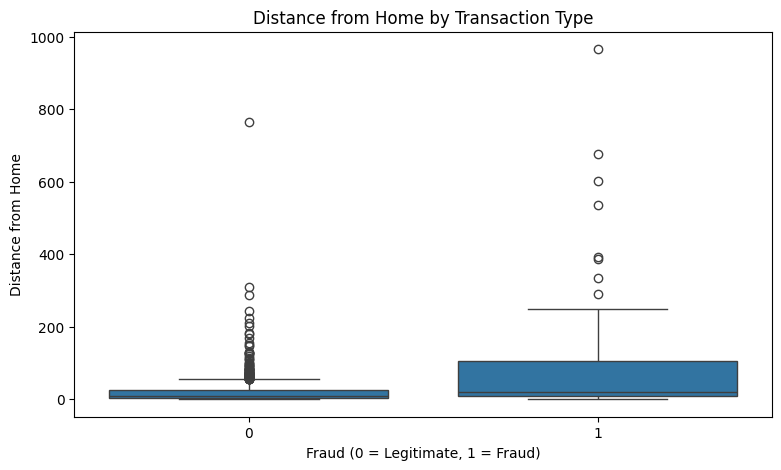

In [15]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='fraud',
    y='distance_from_home'
)

plt.title('Distance from Home by Transaction Type')
plt.xlabel('Fraud (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Distance from Home')

plt.show()

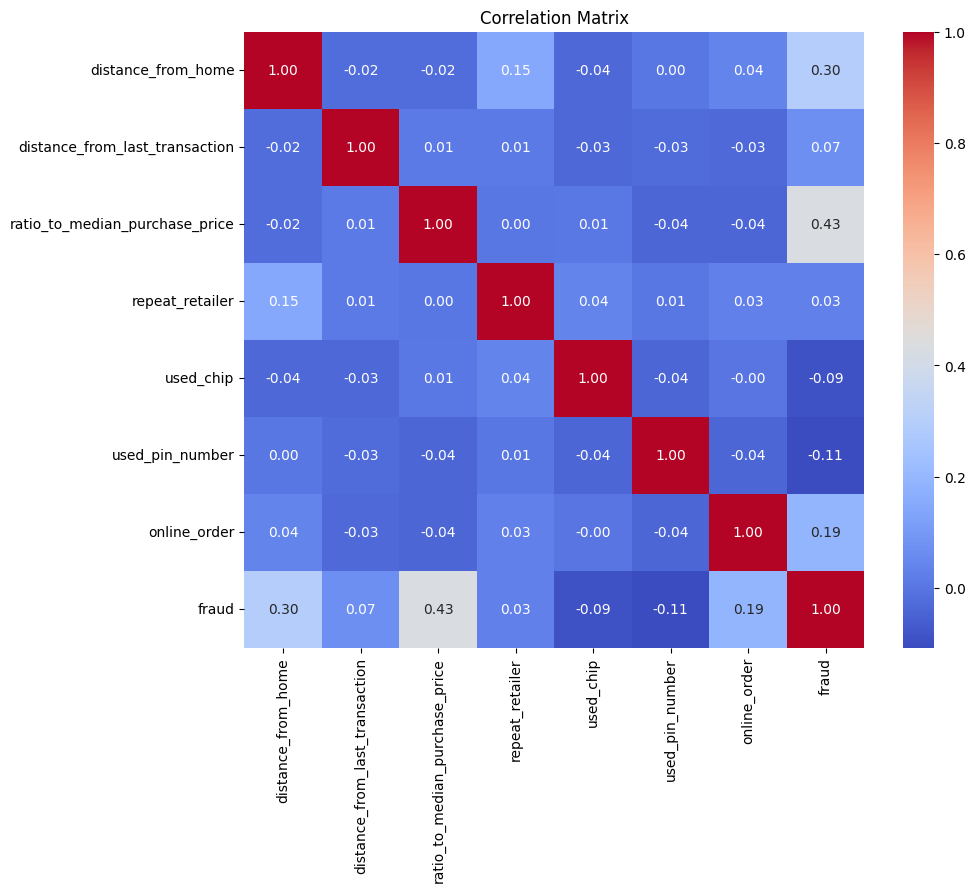

In [16]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')

plt.show()